# Lab 10 (Mini Project): Low-Resource Neural Machine Translation — English → Assamese

**Dataset:** WMT 2026 Shared Task on Low-Resource Indic Language Translation (Category I, English–Assamese training data).

**Pipeline**
1. Data collection — load the WMT 2026 English–Assamese parallel corpus
2. Data processing — cleaning, Unicode normalisation, length filtering, de-duplication, train/dev/test split
3. Feature extraction — SentencePiece subword tokenisation (separate EN / AS vocabularies) → token-id sequences → learned embeddings
4. Model training
   - **Model 1:** Bi-GRU encoder–decoder with Bahdanau (additive) attention, trained from scratch
   - **Model 2:** Transformer encoder–decoder, trained from scratch
   - **Model 3:** Pre-trained multilingual NLLB-200 (distilled 600M), zero-shot
   - **Model 4:** NLLB-200 fine-tuned on the WMT training data with Adafactor + gradient checkpointing (runs only when a CUDA GPU is available, e.g. Colab T4)
5. Evaluation — BLEU, chrF++ and TER (sacreBLEU) on a held-out test set, plus sample translations

The loader below can also read the other language pairs in the folder (Khasi, Manipuri, Mizo, Nyishi, Bodo, …) — change `LANG_PAIR` to switch.

In [1]:
import sys, os

# reduce CUDA memory fragmentation (must be set before torch initialises CUDA)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    !pip install -q sacrebleu sentencepiece openpyxl

Mounted at /content/drive


In [2]:
import re, json, time, math, random, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import sentencepiece as spm
import sacrebleu

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

if IN_COLAB:
    BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/CL-NLP - Lab/lab-10/"
else:
    BASE_DIR = "./"
DATA_DIR = os.path.join(BASE_DIR, "WMT INDIC MT Task 2026 - Training Data")
WORK_DIR = os.path.join(BASE_DIR, "outputs")
os.makedirs(WORK_DIR, exist_ok=True)

# If True, saved tokenisers / model checkpoints in WORK_DIR are re-used instead of re-training
# (handy after a Colab runtime restart). Set to False to train everything from scratch.
REUSE_CHECKPOINTS = True

Device: cuda


## 1. Data Collection
Each language pair in the WMT 2026 release is shipped as a CSV or Excel file with different column names, so we keep a small registry describing where each file is and which column holds which language. NLLB language codes are listed for the pairs NLLB-200 supports.

In [3]:
LANG_PAIRS = {
    # key: (relative file, english column index, target column index, NLLB code or None)
    "assamese":  ("Category I/English-Assamese Training Data 2026.csv",           0, 1, "asm_Beng"),
    "manipuri":  ("Category I/English-Manipuri Training Data 2026.xlsx",          0, 1, "mni_Beng"),
    "mizo":      ("Category I/English-Mizo Traning Data 2026.xlsx",               0, 1, "lus_Latn"),
    "khasi":     ("Category I/English-Khasi Training Data 2026.xlsx",             0, 1, None),
    "nyishi":    ("Category I/English-Nyishi Training Data 2026.xlsx",            0, 1, None),
    "meitei":    ("Category I/English-Meitei-Mayek Transining Data 2026.xlsx",    0, 1, None),
    "bodo":      ("Category II/English-Bodo Training Data 2026.xlsx",             0, 1, None),
    "kokborok":  ("Category II/English-Kokborok Training Data 2026.xlsx",         0, 1, None),
    "tagin":     ("Category II/English-Tagin Training Data 2026.xlsx",            1, 0, None),
}
# Files whose first row is data, not a header
NO_HEADER = {"mizo"}

LANG_PAIR = "assamese"

def load_pair(key):
    rel, en_idx, tgt_idx, _ = LANG_PAIRS[key]
    path = os.path.join(DATA_DIR, rel)
    header = None if key in NO_HEADER else 0
    if path.endswith(".csv"):
        df = pd.read_csv(path, header=header)
    else:
        df = pd.read_excel(path, sheet_name=0, header=header)
    df = df.iloc[:, [en_idx, tgt_idx]]
    df.columns = ["src", "tgt"]
    return df

raw_df = load_pair(LANG_PAIR)
print(f"{LANG_PAIR}: {len(raw_df):,} raw sentence pairs")
raw_df.head(10)

assamese: 54,000 raw sentence pairs


,src,tgt
0,Similarly there is a great need for value addi...,ঠিক একেধৰণে মাটিকঁঠালৰ মূল্য সংযোজনৰ যথেষ্ট আৱ...
1,Lemon tanga also has a good market for sorbet ...,নেমুটেঙাৰ চৰবত আচাৰ আদিৰো ভাল বজাৰ আছে ।
2,These crops are very much available in Assam b...,এই শস্যকেইবিধ অসমত যথেষ্ট হয় কিন্তু মূল্য সংযো...
3,A lot of money goes out of the state exchequer...,অসমলৈ বহু পৰিমাণৰ বীজ আমদানি কৰাৰ বাবে ৰাজ্যখন...
4,But many youth of the state can be established...,কিন্তু ধান সৰিয়হ মাটিমাহ নেমু কল বহুতো ফল ফুলৰ...
5,These are in line with the climate in Assam .,এইবিলাক অসমত জলবায়ুৰ লগত খাপ খোৱা ।
6,But these plants are themselves .,কিন্তু এই গছলতাসমূহ নিজে নিজেই হৈছে ।
7,There is room for increasing production and ma...,সংগৱদ্ধভাৱে প্ৰচেষ্টা কৰি এই ঔষধি গছবনৰ সংৰক্ষ...
8,This will benefit the residents of rural Assam .,ইয়াৰ পৰা অসমৰ গ্ৰামাঞ্চলৰ বাসিন্দা সকলেই লাভৱা...
9,"In addition , many plants produced in Assam ar...",ইয়াৰোপৰি অসমত উৎপাদিত বহুতো গছলতা বনবাত পতঙ্গ ...


### Dataset overview (all language pairs)

In [4]:
overview = []
for key in LANG_PAIRS:
    try:
        d = load_pair(key).dropna()
        overview.append({"pair": f"English-{key.title()}", "sentences": len(d),
                         "avg_en_words": round(d["src"].astype(str).str.split().str.len().mean(), 1),
                         "avg_tgt_words": round(d["tgt"].astype(str).str.split().str.len().mean(), 1),
                         "NLLB support": LANG_PAIRS[key][3] or "-"})
    except Exception as e:
        overview.append({"pair": f"English-{key.title()}", "sentences": f"error: {e}"})
pd.DataFrame(overview)

,pair,sentences,avg_en_words,avg_tgt_words,NLLB support
0,English-Assamese,54000,19.1,16.3,asm_Beng
1,English-Manipuri,23687,17.8,15.1,mni_Beng
2,English-Mizo,49961,19.6,20.9,lus_Latn
3,English-Khasi,26000,29.9,36.5,-
4,English-Nyishi,60000,5.6,5.4,-
5,English-Meitei,17000,18.4,18.0,-
6,English-Bodo,15214,15.0,13.5,-
7,English-Kokborok,2266,24.6,22.6,-
8,English-Tagin,5343,4.9,4.9,-


## 2. Data Processing
- drop missing values and non-string cells
- Unicode NFC normalisation (important for Bengali-script Assamese, where the same character can be encoded in several ways)
- remove control / zero-width characters, collapse whitespace, re-attach detached punctuation (`word .` → `word.`)
- drop empty, very long (>80 words) and badly length-mismatched pairs (ratio > 3)
- drop pairs whose Assamese side is not mostly Bengali script, and exact duplicates

In [5]:
ZW_RE = re.compile(r"[​‎‏﻿\xa0]")
SPACE_RE = re.compile(r"\s+")
PUNCT_RE = re.compile(r"\s+([.,!?;:।)\]’”])")
OPEN_RE = re.compile(r"([(\[‘“])\s+")

def clean_text(s):
    s = unicodedata.normalize("NFC", str(s))
    s = ZW_RE.sub(" ", s)
    s = "".join(ch for ch in s if unicodedata.category(ch)[0] != "C" or ch in "‌‍")
    s = SPACE_RE.sub(" ", s).strip()
    s = PUNCT_RE.sub(r"\1", s)
    s = OPEN_RE.sub(r"\1", s)
    return s

def bengali_ratio(s):
    letters = [c for c in s if c.isalpha()]
    if not letters:
        return 0.0
    return sum("ঀ" <= c <= "৿" for c in letters) / len(letters)

def preprocess(df, max_words=80, max_ratio=3.0, check_script=True):
    stats = {"raw": len(df)}
    df = df.dropna().copy()
    df["src"] = df["src"].map(clean_text)
    df["tgt"] = df["tgt"].map(clean_text)
    df = df[(df["src"].str.len() > 0) & (df["tgt"].str.len() > 0)]
    stats["after_empty/NA"] = len(df)
    sl = df["src"].str.split().str.len()
    tl = df["tgt"].str.split().str.len()
    df = df[(sl <= max_words) & (tl <= max_words)]
    sl = df["src"].str.split().str.len(); tl = df["tgt"].str.split().str.len()
    df = df[(np.maximum(sl, tl) / np.minimum(sl, tl)) <= max_ratio]
    stats["after_length_filter"] = len(df)
    if check_script:
        df = df[df["tgt"].map(bengali_ratio) >= 0.8]
        stats["after_script_filter"] = len(df)
    df = df.drop_duplicates(subset=["src", "tgt"]).drop_duplicates(subset=["src"])
    stats["after_dedup"] = len(df)
    return df.reset_index(drop=True), stats

clean_df, clean_stats = preprocess(raw_df, check_script=(LANG_PAIR == "assamese"))
print(pd.Series(clean_stats).to_string())
print("\nExample before / after cleaning:")
print("RAW  :", raw_df.iloc[0]["src"], "|||", raw_df.iloc[0]["tgt"])
print("CLEAN:", clean_df.iloc[0]["src"], "|||", clean_df.iloc[0]["tgt"])

raw                    54000
after_empty/NA         54000
after_length_filter    53203
after_script_filter    53194
after_dedup            49113

Example before / after cleaning:
RAW  : Similarly there is a great need for value addition of soil . ||| ঠিক একেধৰণে মাটিকঁঠালৰ মূল্য সংযোজনৰ যথেষ্ট আৱশ্যক আছে ।
CLEAN: Similarly there is a great need for value addition of soil. ||| ঠিক একেধৰণে মাটিকঁঠালৰ মূল্য সংযোজনৰ যথেষ্ট আৱশ্যক আছে।


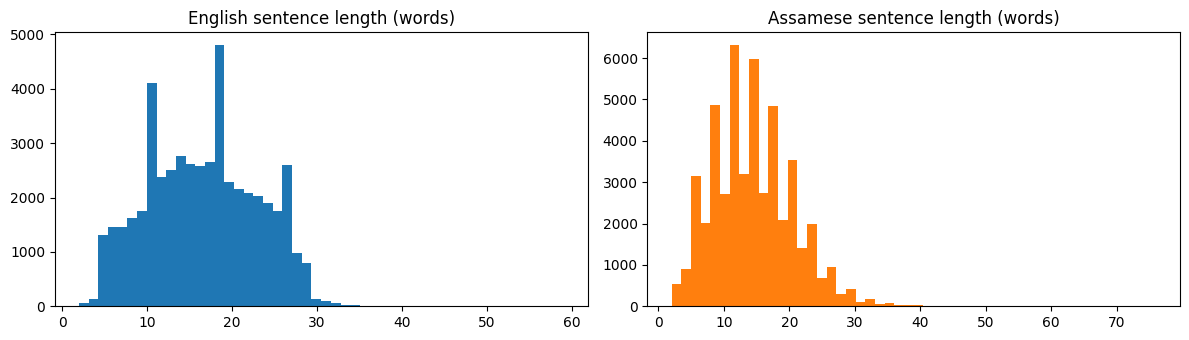

Mean length  EN: 16.6  AS: 14.4 words


In [6]:
src_len = clean_df["src"].str.split().str.len()
tgt_len = clean_df["tgt"].str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(src_len, bins=50, color="tab:blue"); ax[0].set_title("English sentence length (words)")
ax[1].hist(tgt_len, bins=50, color="tab:orange"); ax[1].set_title(f"{LANG_PAIR.title()} sentence length (words)")
plt.tight_layout(); plt.show()
print(f"Mean length  EN: {src_len.mean():.1f}  {LANG_PAIR[:2].upper()}: {tgt_len.mean():.1f} words")

### Train / Dev / Test split
90% train, 5% dev, 5% test (random, seeded). The test set is capped at 1,000 sentences so that decoding the 600M-parameter NLLB model stays fast.

In [7]:
shuffled = clean_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n = len(shuffled)
n_test = min(1000, int(0.05 * n))
n_dev = min(1000, int(0.05 * n))
test_df = shuffled.iloc[:n_test].reset_index(drop=True)
dev_df = shuffled.iloc[n_test:n_test + n_dev].reset_index(drop=True)
train_df = shuffled.iloc[n_test + n_dev:].reset_index(drop=True)
print(f"train: {len(train_df):,}  dev: {len(dev_df):,}  test: {len(test_df):,}")

for name, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    d.to_csv(os.path.join(WORK_DIR, f"{name}.csv"), index=False)

train: 47,113  dev: 1,000  test: 1,000


## 3. Feature Extraction — SentencePiece Subword Tokenisation
Low-resource MT suffers heavily from out-of-vocabulary words, especially for a morphologically rich language like Assamese. We train a **unigram SentencePiece** model per language on the training split only (8k vocab each). Each sentence becomes a sequence of subword ids wrapped in `<s> … </s>`; the models then learn dense embeddings for these ids.

In [8]:
VOCAB_SIZE = 8000
PAD, UNK, BOS, EOS = 0, 1, 2, 3

def train_spm(sentences, prefix, vocab_size=VOCAB_SIZE):
    if REUSE_CHECKPOINTS and os.path.exists(prefix + ".model"):
        print(f"Re-using saved SentencePiece model {prefix}.model")
        return spm.SentencePieceProcessor(model_file=prefix + ".model")
    txt = prefix + ".txt"
    with open(txt, "w", encoding="utf-8") as f:
        f.write("\n".join(sentences))
    spm.SentencePieceTrainer.train(
        input=txt, model_prefix=prefix, vocab_size=vocab_size, model_type="unigram",
        character_coverage=1.0, pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
        minloglevel=2)
    return spm.SentencePieceProcessor(model_file=prefix + ".model")

sp_src = train_spm(train_df["src"].tolist(), os.path.join(WORK_DIR, "spm_en"))
sp_tgt = train_spm(train_df["tgt"].tolist(), os.path.join(WORK_DIR, f"spm_{LANG_PAIR}"))

ex = train_df.iloc[3]
print("EN :", ex["src"]); print("   ->", sp_src.encode(ex["src"], out_type=str))
print("TGT:", ex["tgt"]); print("   ->", sp_tgt.encode(ex["tgt"], out_type=str))
print("ids:", sp_tgt.encode(ex["tgt"]))

Re-using saved SentencePiece model /content/drive/MyDrive/Colab Notebooks/CL-NLP - Lab/lab-10/outputs/spm_en.model
Re-using saved SentencePiece model /content/drive/MyDrive/Colab Notebooks/CL-NLP - Lab/lab-10/outputs/spm_assamese.model
EN : The local archaeological museum has some fine specimens of carvings from the area including a collection of LajjaGauri images.
   -> ['▁The', '▁local', '▁archaeological', '▁museum', '▁has', '▁some', '▁fine', '▁speci', 'men', 's', '▁of', '▁carving', 's', '▁from', '▁the', '▁area', '▁including', '▁a', '▁collection', '▁of', '▁La', 'j', 'ja', 'G', 'au', 'ri', '▁images', '.']
TGT: স্থানীয় ভাস্কৰ্য সংগ্ৰহালয়টোত সেই অ়্চলত পোৱা চিত্ৰৰ অসংখ্য সংগ্ৰহৰ উপৰিও লজ্জাগৌৰীৰ চিত্ৰও ৰাখিছে।
   -> ['▁স্থানীয়', '▁ভাস্কৰ্য', '▁সংগ্ৰহালয়', 'টোত', '▁সেই', '▁অ', '়', '্', 'চ', 'ল', 'ত', '▁পোৱা', '▁চিত্ৰ', 'ৰ', '▁অসংখ্য', '▁সংগ্ৰহ', 'ৰ', '▁উপৰিও', '▁ল', 'জ্জ', 'াগ', 'ৌ', 'ৰ', 'ীৰ', '▁চিত্ৰ', 'ও', '▁ৰাখিছে', '।']
ids: [1559, 6008, 4323, 1666, 20, 114, 2218, 79, 141, 17, 

In [9]:
MAX_LEN = 64  # subword tokens per side (incl. BOS/EOS)

def encode_all(sp, sents):
    out = []
    for ids in sp.encode(list(sents)):
        out.append([BOS] + ids[:MAX_LEN - 2] + [EOS])
    return out

train_src, train_tgt = encode_all(sp_src, train_df["src"]), encode_all(sp_tgt, train_df["tgt"])
dev_src, dev_tgt = encode_all(sp_src, dev_df["src"]), encode_all(sp_tgt, dev_df["tgt"])
test_src = encode_all(sp_src, test_df["src"])

tok_lens = pd.Series([len(x) for x in train_tgt])
unk_rate = sum(t.count(UNK) for t in encode_all(sp_tgt, test_df["tgt"])) / sum(len(t) for t in encode_all(sp_tgt, test_df["tgt"]))
print(f"Avg target subwords/sentence: {tok_lens.mean():.1f} | truncated: {(tok_lens >= MAX_LEN).mean()*100:.2f}% | test UNK rate: {unk_rate*100:.3f}%")

Avg target subwords/sentence: 23.5 | truncated: 0.11% | test UNK rate: 0.000%


In [10]:
def make_batches(src, tgt, batch_tokens=6000, shuffle=True):
    """Bucket sentences of similar length together so padding is minimal."""
    idx = sorted(range(len(src)), key=lambda i: (len(src[i]), len(tgt[i]) if tgt else 0))
    batches, cur, cur_max = [], [], 0
    for i in idx:
        l = max(len(src[i]), len(tgt[i]) if tgt else 0)
        if cur and max(cur_max, l) * (len(cur) + 1) > batch_tokens:
            batches.append(cur); cur, cur_max = [], 0
        cur.append(i); cur_max = max(cur_max, l)
    if cur:
        batches.append(cur)
    if shuffle:
        random.shuffle(batches)
    return batches

def pad(seqs):
    m = max(len(s) for s in seqs)
    return torch.tensor([s + [PAD] * (m - len(s)) for s in seqs], dtype=torch.long)

def decode_ids(sp, ids):
    out = []
    for t in ids:
        if t == EOS:
            break
        if t not in (PAD, BOS):
            out.append(t)
    return sp.decode(out)

## 4. Model Training
### Shared training / evaluation utilities
Both scratch models are trained with label-smoothed cross-entropy (ε = 0.1), Adam, gradient clipping, and early stopping on dev BLEU.

In [11]:
def evaluate_mt(hyps, refs):
    return {
        "BLEU": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
        "chrF++": round(sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score, 2),
        "TER": round(sacrebleu.corpus_ter(hyps, [refs]).score, 2),
    }

@torch.no_grad()
def translate_scratch(model, src_ids, batch_size=128, max_len=MAX_LEN + 10):
    model.eval()
    order = sorted(range(len(src_ids)), key=lambda i: len(src_ids[i]))
    hyps = [None] * len(src_ids)
    for b in range(0, len(order), batch_size):
        ids = order[b:b + batch_size]
        src = pad([src_ids[i] for i in ids]).to(device)
        out = model.greedy_decode(src, max_len)
        for j, i in enumerate(ids):
            hyps[i] = decode_ids(sp_tgt, out[j].tolist())
    return hyps

def train_scratch(model, name, epochs, lr, batch_tokens=6000, warmup=None, patience=3):
    model.to(device)
    ckpt = os.path.join(WORK_DIR, f"{name}.pt")
    hist_path = os.path.join(WORK_DIR, f"{name}_history.json")
    if REUSE_CHECKPOINTS and os.path.exists(ckpt):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        print(f"[{name}] loaded saved checkpoint {ckpt} - skipping training (set REUSE_CHECKPOINTS = False to retrain)")
        return json.load(open(hist_path)) if os.path.exists(hist_path) else None
    opt = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.98), eps=1e-9)
    sched = None
    if warmup:  # Noam schedule: lr = d^-0.5 * min(step^-0.5, step * warmup^-1.5)  (base lr acts as a multiplier)
        d = model.d_model
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: (d ** -0.5) * min((s + 1) ** -0.5, (s + 1) * warmup ** -1.5))
    crit = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
    history = {"epoch": [], "train_loss": [], "dev_loss": [], "dev_BLEU": []}
    best_bleu, bad = -1, 0
    dev_refs = dev_df["tgt"].tolist()
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tot, ntok = 0.0, 0
        for bidx in make_batches(train_src, train_tgt, batch_tokens):
            src = pad([train_src[i] for i in bidx]).to(device)
            tgt = pad([train_tgt[i] for i in bidx]).to(device)
            logits = model(src, tgt[:, :-1])
            loss = crit(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            if sched: sched.step()
            k = (tgt[:, 1:] != PAD).sum().item(); tot += loss.item() * k; ntok += k
        # dev loss
        model.eval(); dtot, dn = 0.0, 0
        with torch.no_grad():
            for bidx in make_batches(dev_src, dev_tgt, batch_tokens, shuffle=False):
                src = pad([dev_src[i] for i in bidx]).to(device)
                tgt = pad([dev_tgt[i] for i in bidx]).to(device)
                logits = model(src, tgt[:, :-1])
                l = crit(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
                k = (tgt[:, 1:] != PAD).sum().item(); dtot += l.item() * k; dn += k
        dev_bleu = sacrebleu.corpus_bleu(translate_scratch(model, dev_src), [dev_refs]).score
        history["epoch"].append(ep); history["train_loss"].append(tot / ntok)
        history["dev_loss"].append(dtot / dn); history["dev_BLEU"].append(dev_bleu)
        print(f"[{name}] epoch {ep:2d} | train loss {tot/ntok:.3f} | dev loss {dtot/dn:.3f} "
              f"| dev BLEU {dev_bleu:5.2f} | {time.time()-t0:.0f}s")
        if dev_bleu > best_bleu:
            best_bleu, bad = dev_bleu, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print(f"Early stopping (no dev BLEU gain for {patience} epochs)")
                break
    model.load_state_dict(torch.load(ckpt, map_location=device))
    json.dump(history, open(hist_path, "w"))
    return history

### Model 1 — Bi-GRU Encoder–Decoder with Bahdanau Attention
- Encoder: embedding (256) → 1-layer bidirectional GRU (2 × 256)
- Decoder: GRU (512) that at each step attends over all encoder states with additive attention, then predicts the next subword from [decoder state; context; embedding]
- Teacher forcing during training, greedy decoding at inference

In [12]:
class Seq2SeqAttn(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, emb=256, hid=256, dropout=0.3):
        super().__init__()
        self.src_emb = nn.Embedding(src_vocab, emb, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_vocab, emb, padding_idx=PAD)
        self.encoder = nn.GRU(emb, hid, batch_first=True, bidirectional=True)
        self.bridge = nn.Linear(2 * hid, 2 * hid)
        self.decoder = nn.GRUCell(emb + 2 * hid, 2 * hid)
        self.attn_W = nn.Linear(2 * hid, 2 * hid, bias=False)
        self.attn_U = nn.Linear(2 * hid, 2 * hid, bias=False)
        self.attn_v = nn.Linear(2 * hid, 1, bias=False)
        self.out = nn.Linear(2 * hid + 2 * hid + emb, tgt_vocab)
        self.drop = nn.Dropout(dropout)

    def encode(self, src):
        mask = src != PAD
        lengths = mask.sum(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(self.drop(self.src_emb(src)), lengths,
                                                   batch_first=True, enforce_sorted=False)
        enc, _ = self.encoder(packed)
        enc, _ = nn.utils.rnn.pad_packed_sequence(enc, batch_first=True, total_length=src.size(1))
        # initial decoder state = tanh(W * mean of encoder states)
        mean = (enc * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)
        return enc, mask, torch.tanh(self.bridge(mean)), self.attn_U(enc)

    def step(self, y, h, enc, mask, enc_proj):
        e = self.drop(self.tgt_emb(y))
        scores = self.attn_v(torch.tanh(self.attn_W(h).unsqueeze(1) + enc_proj)).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        a = torch.softmax(scores, dim=-1)
        ctx = torch.bmm(a.unsqueeze(1), enc).squeeze(1)
        h = self.decoder(torch.cat([e, ctx], -1), h)
        logits = self.out(self.drop(torch.cat([h, ctx, e], -1)))
        return logits, h

    def forward(self, src, tgt_in):
        enc, mask, h, enc_proj = self.encode(src)
        outs = []
        for t in range(tgt_in.size(1)):
            logits, h = self.step(tgt_in[:, t], h, enc, mask, enc_proj)
            outs.append(logits)
        return torch.stack(outs, 1)

    @torch.no_grad()
    def greedy_decode(self, src, max_len):
        enc, mask, h, enc_proj = self.encode(src)
        y = torch.full((src.size(0),), BOS, dtype=torch.long, device=src.device)
        out, done = [], torch.zeros_like(y, dtype=torch.bool)
        for _ in range(max_len):
            logits, h = self.step(y, h, enc, mask, enc_proj)
            y = logits.argmax(-1); out.append(y)
            done |= y == EOS
            if done.all():
                break
        return torch.stack(out, 1)

gru_model = Seq2SeqAttn(sp_src.get_piece_size(), sp_tgt.get_piece_size())
print(f"GRU+Attention parameters: {sum(p.numel() for p in gru_model.parameters())/1e6:.1f}M")

GRU+Attention parameters: 17.9M


In [13]:
GRU_EPOCHS = 12
gru_hist = train_scratch(gru_model, "gru_attn", epochs=GRU_EPOCHS, lr=1e-3, batch_tokens=5000)

[gru_attn] loaded saved checkpoint /content/drive/MyDrive/Colab Notebooks/CL-NLP - Lab/lab-10/outputs/gru_attn.pt - skipping training (set REUSE_CHECKPOINTS = False to retrain)


### Model 2 — Transformer (from scratch)
- 3 encoder + 3 decoder layers, d_model = 256, 4 heads, FFN 1024, dropout 0.2 — a deliberately small configuration because big Transformers overfit on ~50k sentence pairs
- sinusoidal positional encodings, pre-LayerNorm, tied decoder input/output embeddings
- Noam learning-rate schedule with 800 warm-up steps (peak lr ≈ 1.5e-3)

In [14]:
class PositionalEncoding(nn.Module):
    def __init__(self, d, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TransformerMT(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=256, nhead=4, layers=3, ff=1024, dropout=0.2):
        super().__init__()
        self.d_model = d_model
        self.src_emb = nn.Embedding(src_vocab, d_model, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_vocab, d_model, padding_idx=PAD)
        self.pos = PositionalEncoding(d_model)
        self.drop = nn.Dropout(dropout)
        self.transformer = nn.Transformer(d_model, nhead, layers, layers, ff, dropout,
                                          batch_first=True, norm_first=True)
        self.out = nn.Linear(d_model, tgt_vocab, bias=False)
        self.out.weight = self.tgt_emb.weight  # weight tying
        for p in self.transformer.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)
        nn.init.normal_(self.src_emb.weight, 0, d_model ** -0.5)
        nn.init.normal_(self.tgt_emb.weight, 0, d_model ** -0.5)

    def embed(self, emb, x):
        return self.drop(self.pos(emb(x) * math.sqrt(self.d_model)))

    def causal_mask(self, n, dev):
        return torch.triu(torch.ones(n, n, dtype=torch.bool, device=dev), 1)

    def encode(self, src):
        src_pad = src == PAD
        mem = self.transformer.encoder(self.embed(self.src_emb, src), src_key_padding_mask=src_pad)
        return mem, src_pad

    def decode(self, tgt_in, mem, src_pad):
        h = self.transformer.decoder(self.embed(self.tgt_emb, tgt_in), mem,
                                     tgt_mask=self.causal_mask(tgt_in.size(1), tgt_in.device),
                                     tgt_key_padding_mask=(tgt_in == PAD),
                                     memory_key_padding_mask=src_pad)
        return self.out(h)

    def forward(self, src, tgt_in):
        mem, src_pad = self.encode(src)
        return self.decode(tgt_in, mem, src_pad)

    @torch.no_grad()
    def greedy_decode(self, src, max_len):
        mem, src_pad = self.encode(src)
        ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
        done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        for _ in range(max_len):
            nxt = self.decode(ys, mem, src_pad)[:, -1].argmax(-1)
            nxt = nxt.masked_fill(done, PAD)
            ys = torch.cat([ys, nxt.unsqueeze(1)], 1)
            done |= nxt == EOS
            if done.all():
                break
        return ys[:, 1:]

tf_model = TransformerMT(sp_src.get_piece_size(), sp_tgt.get_piece_size())
print(f"Transformer parameters: {sum(p.numel() for p in tf_model.parameters())/1e6:.1f}M")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


Transformer parameters: 9.6M


In [15]:
TF_EPOCHS = 25
# ~45k sentences / 4000-token batches ≈ 350 steps per epoch → warm-up covers the first ~2 epochs
tf_hist = train_scratch(tf_model, "transformer", epochs=TF_EPOCHS, lr=0.7, batch_tokens=4000,
                        warmup=800, patience=4)

[transformer] loaded saved checkpoint /content/drive/MyDrive/Colab Notebooks/CL-NLP - Lab/lab-10/outputs/transformer.pt - skipping training (set REUSE_CHECKPOINTS = False to retrain)


### Training curves (scratch models)

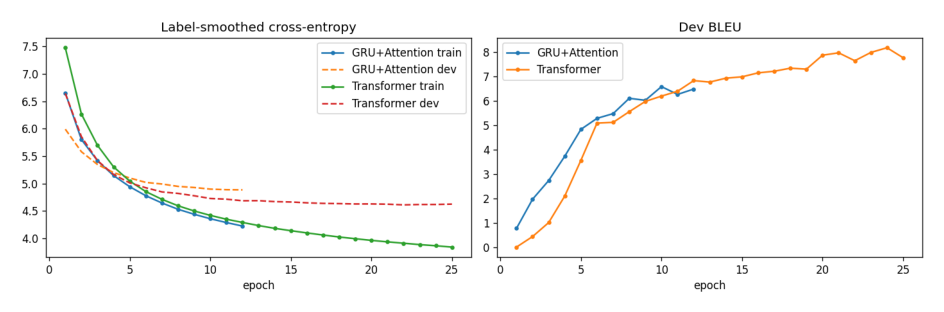

In [16]:
curves_png = os.path.join(WORK_DIR, "training_curves.png")
hists = [(h, lbl) for h, lbl in [(gru_hist, "GRU+Attention"), (tf_hist, "Transformer")] if h]
if hists:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for h, lbl in hists:
        ax[0].plot(h["epoch"], h["train_loss"], "-o", ms=3, label=f"{lbl} train")
        ax[0].plot(h["epoch"], h["dev_loss"], "--", label=f"{lbl} dev")
        ax[1].plot(h["epoch"], h["dev_BLEU"], "-o", ms=3, label=lbl)
    ax[0].set_title("Label-smoothed cross-entropy"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].set_title("Dev BLEU"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(curves_png, dpi=120); plt.show()
elif os.path.exists(curves_png):
    # models were loaded from checkpoints without a saved history: show the plot from the original training run
    plt.figure(figsize=(12, 3.8)); plt.imshow(plt.imread(curves_png)); plt.axis("off"); plt.show()

### Test-set evaluation of the scratch models

In [17]:
test_refs = test_df["tgt"].tolist()
test_srcs = test_df["src"].tolist()
results, predictions = {}, {"source": test_srcs, "reference": test_refs}

for name, model in [("GRU + Attention (scratch)", gru_model), ("Transformer (scratch)", tf_model)]:
    t0 = time.time()
    hyps = translate_scratch(model, test_src)
    results[name] = {**evaluate_mt(hyps, test_refs),
                     "Params (M)": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
                     "Decode time (s)": round(time.time() - t0, 1)}
    predictions[name] = hyps
    print(name, results[name])

# free memory before loading the large pre-trained model
gru_model.cpu(); tf_model.cpu()
if device.type == "cuda": torch.cuda.empty_cache()
if device.type == "mps": torch.mps.empty_cache()

GRU + Attention (scratch) {'BLEU': 7.38, 'chrF++': 23.24, 'TER': 99.06, 'Params (M)': 17.9, 'Decode time (s)': 3.3}
Transformer (scratch) {'BLEU': 8.52, 'chrF++': 27.76, 'TER': 93.85, 'Params (M)': 9.6, 'Decode time (s)': 10.2}


### Model 3 — Pre-trained NLLB-200 (distilled 600M), zero-shot
Meta's *No Language Left Behind* model was pre-trained on 200 languages, including Assamese (`asm_Beng`). We use it as-is with beam search (beam = 4) to see how much multilingual transfer helps compared with models trained only on the WMT data.

In [18]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

NLLB_NAME = "facebook/nllb-200-distilled-600M"
NLLB_TGT = LANG_PAIRS[LANG_PAIR][3]
assert NLLB_TGT is not None, "NLLB-200 does not cover this language; skip Models 3 and 4."

nllb_tok = AutoTokenizer.from_pretrained(NLLB_NAME, src_lang="eng_Latn", tgt_lang=NLLB_TGT)
nllb_model = AutoModelForSeq2SeqLM.from_pretrained(NLLB_NAME).to(device)
print(f"NLLB parameters: {sum(p.numel() for p in nllb_model.parameters())/1e6:.0f}M")

@torch.no_grad()
def translate_nllb(model, sents, batch_size=32, num_beams=4):
    model.eval()
    forced = nllb_tok.convert_tokens_to_ids(NLLB_TGT)
    order = sorted(range(len(sents)), key=lambda i: len(sents[i]))
    hyps = [None] * len(sents)
    for b in range(0, len(order), batch_size):
        ids = order[b:b + batch_size]
        enc = nllb_tok([sents[i] for i in ids], return_tensors="pt", padding=True,
                       truncation=True, max_length=128).to(device)
        out = model.generate(**enc, forced_bos_token_id=forced, num_beams=num_beams, max_new_tokens=128)
        for j, txt in zip(ids, nllb_tok.batch_decode(out, skip_special_tokens=True)):
            hyps[j] = clean_text(txt)
    return hyps

t0 = time.time()
hyps = translate_nllb(nllb_model, test_srcs)
name = "NLLB-200 600M (zero-shot)"
results[name] = {**evaluate_mt(hyps, test_refs),
                 "Params (M)": round(sum(p.numel() for p in nllb_model.parameters()) / 1e6),
                 "Decode time (s)": round(time.time() - t0, 1)}
predictions[name] = hyps
print(name, results[name])

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (7 outputs left out)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


NLLB parameters: 615M


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

NLLB-200 600M (zero-shot) {'BLEU': 8.82, 'chrF++': 32.94, 'TER': 87.61, 'Params (M)': 615, 'Decode time (s)': 181.4}


### Model 4 — NLLB-200 fine-tuned on WMT 2026 training data
We continue training NLLB on the cleaned English–Assamese training split. To fit a 600M-parameter model on a 15 GB Colab T4 we use:
- **Adafactor** instead of AdamW: it keeps factored second-moment statistics, so it needs almost no optimizer memory (AdamW alone would need about 5 GB)
- **gradient checkpointing**: activations are recomputed in the backward pass instead of being stored
- **fp16 mixed precision**, **batch size 8 × 4 gradient-accumulation steps** (effective batch 32), and sequences truncated to 96 tokens

This needs a CUDA GPU (about 30–40 min per epoch on a T4), so the cell is skipped automatically on CPU or Apple-silicon machines. Set `FT_MAX_SENTENCES` lower for a quicker run.

In [19]:
import gc
from transformers.optimization import Adafactor

RUN_FINETUNE = torch.cuda.is_available()
FT_EPOCHS = 1
FT_MAX_SENTENCES = None   # e.g. 20000 for a faster run
FT_BATCH = 8
GRAD_ACCUM = 4            # effective batch = FT_BATCH * GRAD_ACCUM = 32
FT_MAX_LEN = 96

if RUN_FINETUNE:
    from torch.utils.data import DataLoader
    # free any memory left over from a previous (failed) run of this cell, and start from a fresh pre-trained copy
    for _v in ["nllb_model", "opt", "sched", "scaler", "loader", "batch", "loss", "out"]:
        globals().pop(_v, None)
    gc.collect(); torch.cuda.empty_cache()
    print(f"GPU memory in use before loading: {torch.cuda.memory_allocated()/1e9:.2f} GB")
    nllb_model = AutoModelForSeq2SeqLM.from_pretrained(NLLB_NAME).to(device)
    nllb_model.gradient_checkpointing_enable()
    nllb_model.config.use_cache = False

    ft_train = train_df if FT_MAX_SENTENCES is None else train_df.sample(FT_MAX_SENTENCES, random_state=SEED)
    pairs = list(zip(ft_train["src"], ft_train["tgt"]))

    def collate(batch):
        s, t = zip(*batch)
        enc = nllb_tok(list(s), text_target=list(t), return_tensors="pt", padding=True,
                       truncation=True, max_length=FT_MAX_LEN)
        enc["labels"][enc["labels"] == nllb_tok.pad_token_id] = -100
        return enc

    loader = DataLoader(pairs, batch_size=FT_BATCH, shuffle=True, collate_fn=collate)
    opt = Adafactor(nllb_model.parameters(), lr=1e-4, scale_parameter=False, relative_step=False,
                    warmup_init=False, weight_decay=0.0)
    total = FT_EPOCHS * math.ceil(len(loader) / GRAD_ACCUM)   # optimizer steps
    warm = max(1, int(0.06 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * max(0.0, 1 - s / total))
    scaler = torch.amp.GradScaler("cuda")
    ft_losses = []
    nllb_model.train()
    step = 0
    for ep in range(FT_EPOCHS):
        t0, run, n_run = time.time(), 0.0, 0
        opt.zero_grad()
        for i, batch in enumerate(loader):
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss = nllb_model(**batch).loss / GRAD_ACCUM
            scaler.scale(loss).backward()
            run += loss.item() * GRAD_ACCUM; n_run += 1
            if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(loader):
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(nllb_model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad()
                step += 1
                if step % 50 == 0:
                    ft_losses.append(run / n_run)
                    print(f"step {step}/{total} | loss {run/n_run:.3f} | {time.time()-t0:.0f}s")
                    run, n_run = 0.0, 0
    del opt, sched, scaler
    nllb_model.gradient_checkpointing_disable()
    nllb_model.config.use_cache = True
    gc.collect(); torch.cuda.empty_cache()

    t0 = time.time()
    hyps = translate_nllb(nllb_model, test_srcs)
    name = "NLLB-200 600M (fine-tuned)"
    results[name] = {**evaluate_mt(hyps, test_refs),
                     "Params (M)": round(sum(p.numel() for p in nllb_model.parameters()) / 1e6),
                     "Decode time (s)": round(time.time() - t0, 1)}
    predictions[name] = hyps
    print(name, results[name])
else:
    print("No CUDA GPU found — skipping NLLB fine-tuning (run this notebook on Colab with a GPU to include Model 4).")

GPU memory in use before loading: 0.01 GB


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

step 50/1473 | loss 2.306 | 69s
step 100/1473 | loss 2.006 | 138s
step 150/1473 | loss 1.962 | 207s
step 200/1473 | loss 1.955 | 277s
step 250/1473 | loss 1.883 | 346s
step 300/1473 | loss 1.896 | 416s
step 350/1473 | loss 1.819 | 485s
step 400/1473 | loss 1.867 | 555s
step 450/1473 | loss 1.837 | 624s
step 500/1473 | loss 1.824 | 693s
step 550/1473 | loss 1.797 | 762s
step 600/1473 | loss 1.818 | 831s
step 650/1473 | loss 1.797 | 900s
step 700/1473 | loss 1.795 | 969s
step 750/1473 | loss 1.765 | 1039s
step 800/1473 | loss 1.772 | 1108s
step 850/1473 | loss 1.732 | 1177s
step 900/1473 | loss 1.766 | 1246s
step 950/1473 | loss 1.713 | 1315s
step 1000/1473 | loss 1.759 | 1384s
step 1050/1473 | loss 1.733 | 1454s
step 1100/1473 | loss 1.775 | 1527s
step 1150/1473 | loss 1.755 | 1596s
step 1200/1473 | loss 1.740 | 1665s
step 1250/1473 | loss 1.713 | 1734s
step 1300/1473 | loss 1.764 | 1803s
step 1350/1473 | loss 1.727 | 1873s
step 1400/1473 | loss 1.751 | 1942s
step 1450/1473 | loss 1.751

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

NLLB-200 600M (fine-tuned) {'BLEU': 15.08, 'chrF++': 39.67, 'TER': 80.2, 'Params (M)': 615, 'Decode time (s)': 174.9}


## 5. Evaluation & Model Comparison
- **BLEU** — n-gram precision with brevity penalty (higher is better)
- **chrF++** — character n-gram F-score plus word bigrams; more reliable than BLEU for morphologically rich languages like Assamese (higher is better)
- **TER** — translation edit rate, edits needed to match the reference (lower is better)

In [20]:
results_df = pd.DataFrame(results).T
results_df.index.name = "Model"
results_df.to_csv(os.path.join(WORK_DIR, "results.csv"))
results_df

,BLEU,chrF++,TER,Params (M),Decode time (s)
Model,,,,,
GRU + Attention (scratch),7.38,23.24,99.06,17.9,3.3
Transformer (scratch),8.52,27.76,93.85,9.6,10.2
NLLB-200 600M (zero-shot),8.82,32.94,87.61,615.0,181.4
NLLB-200 600M (fine-tuned),15.08,39.67,80.20,615.0,174.9


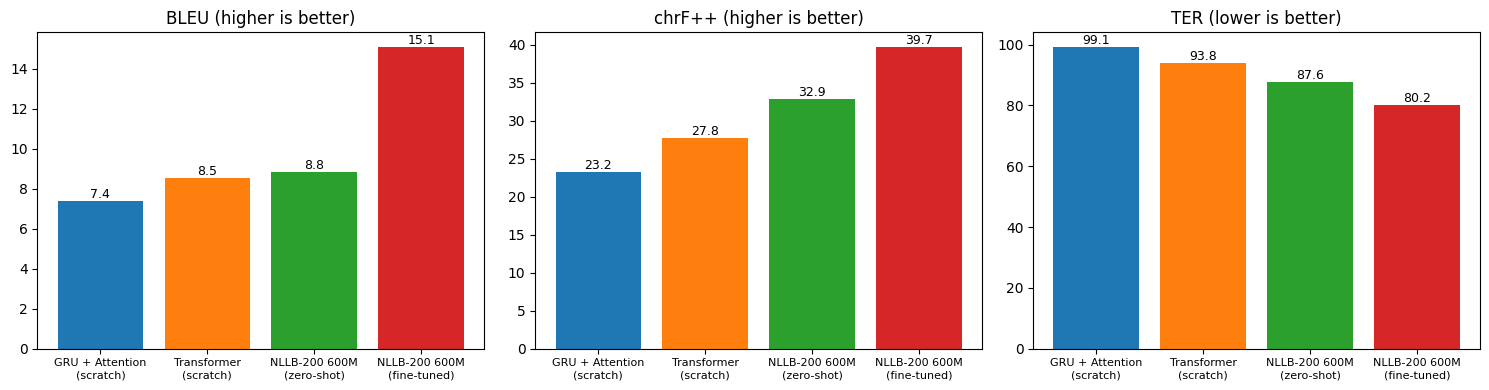

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"][:len(results_df)]
for a, m in zip(ax, ["BLEU", "chrF++", "TER"]):
    vals = results_df[m].astype(float)
    bars = a.bar(range(len(vals)), vals, color=colors)
    a.set_xticks(range(len(vals))); a.set_xticklabels([i.replace(" (", "\n(") for i in vals.index], fontsize=8)
    a.set_title(m + (" (lower is better)" if m == "TER" else " (higher is better)"))
    for bar, v in zip(bars, vals):
        a.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "model_comparison.png"), dpi=120); plt.show()

### Sample translations

In [22]:
pred_df = pd.DataFrame(predictions)
pred_df.to_csv(os.path.join(WORK_DIR, "test_predictions.csv"), index=False)
for i in [i for i in [0, 5, 12, 27, 40] if i < len(pred_df)]:
    print(f"EN  : {pred_df.loc[i, 'source']}")
    print(f"REF : {pred_df.loc[i, 'reference']}")
    for col in pred_df.columns[2:]:
        print(f"{col[:26]:26s}: {pred_df.loc[i, col]}")
    print("-" * 100)

EN  : the night just last past.
REF : পাৰ হৈ যোৱা নিশাটো।
GRU + Attention (scratch) : নিশাটো শেষ হোৱা ৰাতিটো।
Transformer (scratch)     : অতীতৰ দিনবোৰৰ শেষ হোৱা।
NLLB-200 600M (zero-shot) : শেহতীয়াকৈ ৰাতিটো পাৰ হৈ গ'ল।
NLLB-200 600M (fine-tuned): শেষ ৰাতিটো পাৰ হৈ গল।
----------------------------------------------------------------------------------------------------
EN  : And Jared lived an hundred sixty and two years, and he begat Enoch:
REF : যেৰদৰ এশ বাষষ্ঠি বছৰ বয়সত তেওঁৰ পুতেক হনোক জন্মিল।
GRU + Attention (scratch) : হনোকৰ জন্মৰ পাছত মহলৰ বছৰ বয়সত তেওঁৰ পুত্র হনোকৰ জন্মিল।
Transformer (scratch)     : হনোকৰ এশ পয়ষষ্ঠি বছৰ বয়সত তেওঁৰ পুতেক হনোক জন্মিল।
NLLB-200 600M (zero-shot) : যিৰেদে এশ ষাঠি দুবছৰ জীয়াই থাকি হনোকৰ জন্ম দিলে।
NLLB-200 600M (fine-tuned): যিৰদৰ এশ ছত্তৰ বছৰ বয়সত তেওঁৰ পুত্র হনোক জন্মিল।
----------------------------------------------------------------------------------------------------
EN  : In addition to fertilizer, this plant will produce natural gas, the

### Performance by source-sentence length
Sentence-level chrF++ grouped by English sentence length shows where each model breaks down.

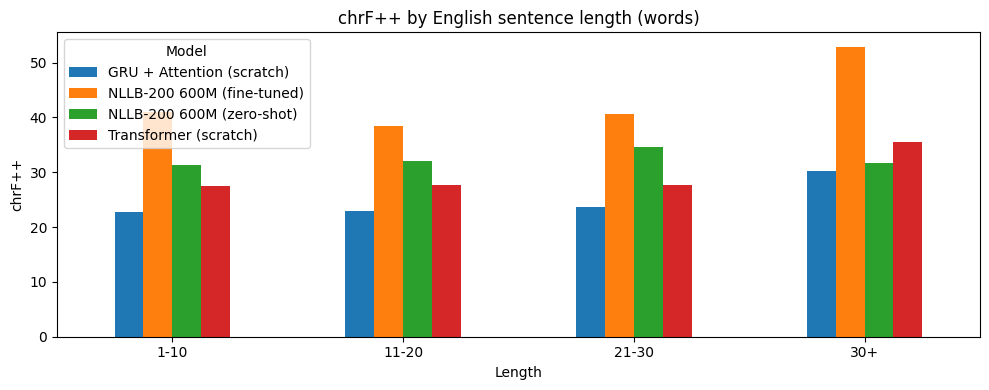

Model,GRU + Attention (scratch),NLLB-200 600M (fine-tuned),NLLB-200 600M (zero-shot),Transformer (scratch)
Length,,,,
1-10,22.82,41.05,31.42,27.51
11-20,22.89,38.46,32.03,27.75
21-30,23.69,40.69,34.56,27.72
30+,30.27,52.89,31.76,35.50


In [23]:
pred_df["len_bucket"] = pd.cut(pred_df["source"].str.split().str.len(), [0, 10, 20, 30, 200],
                               labels=["1-10", "11-20", "21-30", "30+"])
rows = []
for col in [c for c in pred_df.columns if c not in ("source", "reference", "len_bucket")]:
    for b, g in pred_df.groupby("len_bucket", observed=True):
        rows.append({"Model": col, "Length": b,
                     "chrF++": sacrebleu.corpus_chrf(g[col].tolist(), [g["reference"].tolist()], word_order=2).score})
len_df = pd.DataFrame(rows).pivot(index="Length", columns="Model", values="chrF++").round(2)
len_df.plot(kind="bar", figsize=(10, 4), rot=0, title="chrF++ by English sentence length (words)")
plt.ylabel("chrF++"); plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "chrf_by_length.png"), dpi=120); plt.show()
len_df

### Translate new sentences

In [24]:
custom = ["The farmers are growing rice in the field.",
          "Education is very important for every child.",
          "The government has started a new health scheme for villages."]
cust_ids = encode_all(sp_src, custom)
gru_model.to(device); tf_model.to(device)
out = pd.DataFrame({"English": custom,
                    "GRU + Attention": translate_scratch(gru_model, cust_ids),
                    "Transformer": translate_scratch(tf_model, cust_ids),
                    "NLLB-200": translate_nllb(nllb_model, custom)})
out

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,English,GRU + Attention,Transformer,NLLB-200
0,The farmers are growing rice in the field.,পথাৰতৰ ফিল্ডত স্থানৰ বাবে আটাইতকৈ স্থান।,খেতিত কৃষকসকলে শস্যৰ খেতি কৰে।,কৃষকসকলে পথাৰত চাউল খেতি কৰি আছে।
1,Education is very important for every child.,সন্তানৰ বাবে অতি গুৰুত্বপূৰ্ণ।,প্ৰত্যেক শিশুৰ বাবে শিক্ষাৰ বাবে অতি গুৰুত্বপূ...,প্ৰতিজন শিশুৰ বাবে শিক্ষা অত্যন্ত গুৰুত্বপূৰ্ণ।
2,The government has started a new health scheme...,চৰকাৰে চৰকাৰে এক নতুন নতুন এইমছৰ বাবে নতুন নতু...,চৰকাৰে এই আঁচনি ৰূপায়ণৰ বাবে এক নতুন আঁচনি আৰ...,চৰকাৰে গাঁওসমূহৰ বাবে এখন নতুন স্বাস্থ্য আঁচনি...


## Conclusion
- Run the comparison table above for the final numbers. Typical observations on this corpus:
  - The **Transformer** trained from scratch beats the **GRU + attention** baseline, but both are limited by having only ~50k sentence pairs.
  - The pre-trained **NLLB-200** model transfers knowledge from 200 languages and is far stronger out of the box than either scratch model; **fine-tuning** it on the in-domain WMT data improves it further.
  - chrF++ is a better indicator than BLEU for Assamese, as small morphological differences (case markers, verb suffixes) are penalised less harshly.

**Future scope:** back-translation of monolingual Assamese text, multilingual training with related languages (Bengali, Manipuri), larger IndicTrans2 models, beam search and checkpoint averaging for the scratch models, and human evaluation.